In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

In [24]:
data = np.array([3,13,19,24,29])

In [25]:
data.mean(), data.sum() / data.size

(np.float64(17.6), np.float64(17.6))

In [26]:
diff = data - data.mean()
sqr = diff ** 2
sqr_summ = sqr.sum()
est_variance = sqr_summ / (data.size -1)
est_std_dev = est_variance ** 0.5

data.std(), est_std_dev, est_variance

(np.float64(9.024411338142782),
 np.float64(10.089598604503552),
 np.float64(101.80000000000001))

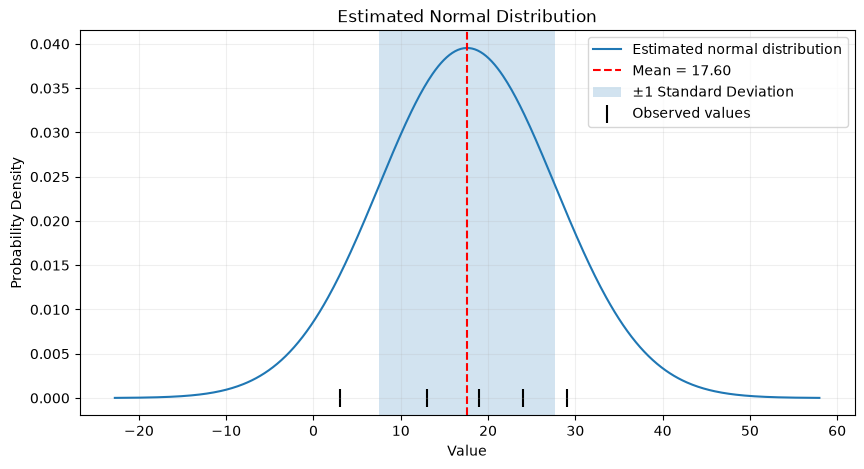

In [27]:


mean = data.mean()
std = data.std(ddof=1)  # Sample standard deviation

# Generate X values for a smooth curve
x = np.linspace(mean - 4 * std, mean + 4 * std, 500)

# Calculate normal probability density
y = norm.pdf(x, loc=mean, scale=std)

plt.figure(figsize=(10, 5))

# Normal distribution curve
plt.plot(x, y, label="Estimated normal distribution")

# Mean
plt.axvline(mean, color="red", linestyle="--",
            label=f"Mean = {mean:.2f}")

# ±1 standard deviation
plt.axvspan(mean - std, mean + std,
            alpha=0.2, label="±1 Standard Deviation")

# Original observations (rug plot)
plt.scatter(data, np.zeros_like(data),
            color="black", marker="|", s=150,
            label="Observed values")

plt.title("Estimated Normal Distribution")
plt.xlabel("Value")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [29]:
ts = pd.Series(np.random.randn(1000), index=pd.date_range("2026-01-01", periods=1000))
ts.head()

2026-01-01   -0.364038
2026-01-02   -0.868790
2026-01-03   -0.834712
2026-01-04    0.724909
2026-01-05   -1.260406
Freq: D, dtype: float64

In [32]:
ts_summed = ts.cumsum()
ts_summed.describe()

count    1000.000000
mean      -11.742692
std         7.312570
min       -29.628980
25%       -18.151166
50%       -10.658397
75%        -6.278060
max         2.471554
dtype: float64

<Axes: >

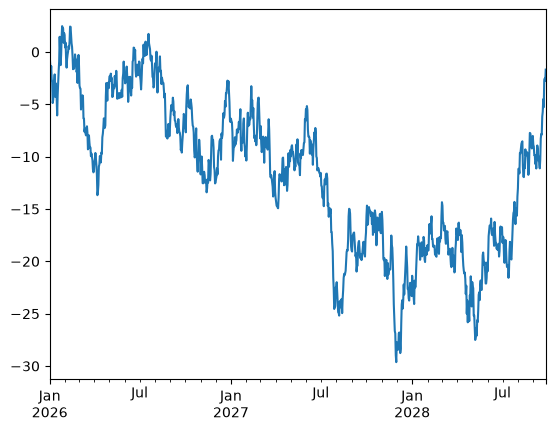

In [31]:
ts_summed.plot()

In [33]:
df = pd.DataFrame(
    np.random.randn(1000, 4), index=ts.index, columns=["A", "B", "C", "D"]
)
df.head()

,A,B,C,D
2026-01-01,0.731329,0.520675,-0.496010,1.257550
2026-01-02,-1.719298,-0.522990,-1.894198,-0.427083
2026-01-03,1.241399,-1.601965,-0.573763,0.161462
2026-01-04,-0.769984,-1.840295,-1.953914,-0.772925
2026-01-05,-0.099975,1.383534,0.854932,-0.778466


In [34]:
df = df.cumsum()
df.head()

,A,B,C,D
2026-01-01,0.731329,0.520675,-0.496010,1.257550
2026-01-02,-0.987970,-0.002315,-2.390208,0.830467
2026-01-03,0.253429,-1.604280,-2.963971,0.991929
2026-01-04,-0.516554,-3.444574,-4.917885,0.219004
2026-01-05,-0.616529,-2.061041,-4.062953,-0.559463


<Figure size 640x480 with 0 Axes>

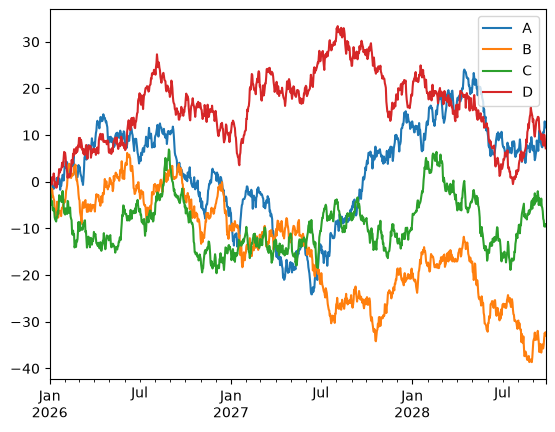

In [41]:
plt.figure()
df.plot()
plt.legend(loc="upper right")  
plt.show()